# Step 4 — PPO optimisation on Walker-v0

**Protocol (same for every experiment):** one change at a time vs the baseline (course TD6 hyperparameters), same hand-designed robot, 1M steps, 8 parallel envs, seeds 31, 32, 33.

**Metrics** (the return saturates at ≈ 10.5 once the goal is reached, see notebook 02):
- `train_steps_to_90%_success` — learning efficiency (lower = better),
- `steps_to_goal_last100` / `test_steps_to_goal` — speed of the robot (lower = better),
- `success_last100_%`, `return_last100` — to check nothing breaks.

**Decision rule:** a change is kept only if the gain is larger than the seed-to-seed spread **and** goes the same way on the 3 seeds.

Shared metric code: [`analysis.py`](../analysis.py).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from ppo import load_body
from analysis import experiment_table, load_run

BODY = load_body("walker")
SEEDS = [31, 32, 33]
METRICS = ["return_last100", "success_last100_%", "steps_to_goal_last100", "test_steps_to_goal",
           "train_steps_to_90%_success"]

baseline = experiment_table("walker_baseline", BODY)
summary = {"baseline": baseline[METRICS].agg(["mean", "std"])}


def compare(name, prefix):
    """Per-seed table of an experiment and its mean ± std next to the baseline."""
    table = experiment_table(prefix, BODY)
    summary[name] = table[METRICS].agg(["mean", "std"])
    display(table.round(1))
    side = pd.DataFrame({k: v.loc["mean"].round(1).astype(str) + " ± " + v.loc["std"].round(1).astype(str)
                         for k, v in [("baseline", summary["baseline"]), (name, summary[name])]})
    display(side)
    return table


def plot_vs_baseline(prefix, label, fname):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for run_prefix, color, lab in [("walker_baseline", "tab:gray", "baseline (TD6)"), (prefix, "tab:blue", label)]:
        for i, s in enumerate(SEEDS):
            ep, _ = load_run(Path(f"../runs/{run_prefix}_s{s}"))
            kw = dict(color=color, alpha=0.8, label=lab if i == 0 else None)
            axes[0].plot(ep["end_step"], ep["episode_return"].rolling(50).mean(), **kw)
            axes[1].plot(ep["end_step"], 100 * ep["success"].rolling(50).mean(), **kw)
            succ = ep[ep["success"]]
            axes[2].plot(succ["end_step"], succ["length"].rolling(50).mean(), **kw)
    axes[0].set(title="Return (moving avg 50 ep)", xlabel="Env steps")
    axes[1].set(title="Success rate % (moving avg 50 ep)", xlabel="Env steps", ylim=(0, 105))
    axes[2].set(title="Steps to goal, successful episodes (moving avg 50)", xlabel="Env steps", ylabel="lower = faster")
    axes[0].legend()
    for ax in axes:
        ax.grid(True)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", dpi=120)
    plt.show()


print("Baseline (3 seeds):")
display(summary["baseline"].round(1))

/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/evogym/envs/base.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Using device: cpu


Using device: cpu


Using device: cpu


Baseline (3 seeds):


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,train_steps_to_90%_success
mean,10.5,97.3,445.5,404.0,482351.8
std,0.1,2.1,5.6,25.2,38811.6


## 4a — Reward normalisation

**Observation (notebook 02):** Walker rewards are tiny (≈ 0.02 per step) — the opposite of Pendulum, where reward normalisation solved the task (−160 vs −502).
**Hypothesis:** rescaling rewards gives the critic targets of a stable, sensible scale → learning starts earlier.
**Change:** `--norm-reward` (divide each reward by the running std of the discounted return). Nothing else changes.

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,10.2,93.0,459.4,439,10.6,396854.3
32,10.5,96.0,464.3,435,10.6,456838.4
33,10.5,90.0,481.0,500,9.5,745685.0


,baseline,4a_norm_reward
return_last100,10.5 ± 0.1,10.4 ± 0.1
success_last100_%,97.3 ± 2.1,93.0 ± 3.0
steps_to_goal_last100,445.5 ± 5.6,468.2 ± 11.3
test_steps_to_goal,404.0 ± 25.2,458.0 ± 36.4
train_steps_to_90%_success,482351.8 ± 38811.6,533125.9 ± 186508.8


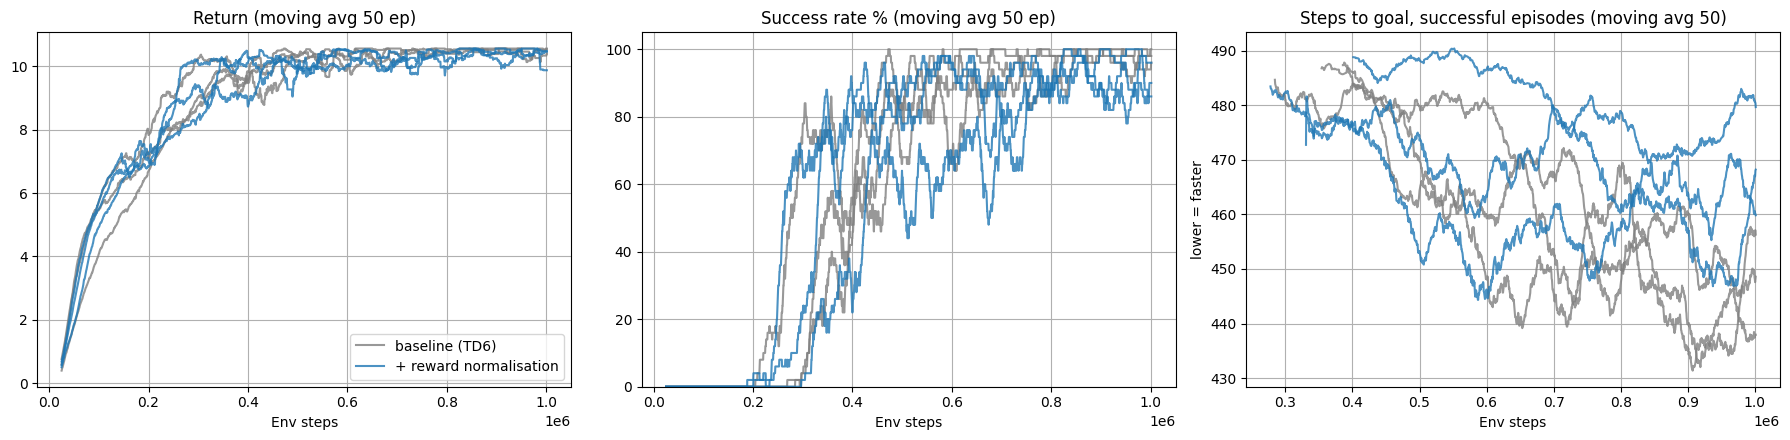

In [2]:
t4a = compare("4a_norm_reward", "walker_4a_normreward")
plot_vs_baseline("walker_4a_normreward", "+ reward normalisation", "04a_norm_reward.png")

### Result 4a — not kept ❌

| Metric | Baseline | + reward normalisation |
|---|---|---|
| Training steps to 90 % success | 482k ± 39k | 533k ± 187k |
| Steps to goal (training, last 100) | 446 ± 6 | 468 ± 11 |
| Steps to goal (deterministic test) | 404 ± 25 | 458 ± 36 (seed 33 does not reach the goal) |
| Success rate (last 100) | 97 ± 2 % | 93 ± 3 % |

- **Slower robot on all 3 seeds** (training steps-to-goal 459 / 464 / 481 vs 439 / 450 / 447) and less reliable.
- **Learning efficiency is not better on average and much less stable:** two seeds reach 90 % success earlier (397k, 457k) but seed 33 needs 746k.
- **Conclusion:** the trick that solved Pendulum does **not** transfer to Walker. Reward normalisation is not kept.

**Why? (hypotheses, not tested):** on Pendulum the problem was returns in the thousands; on Walker the reward is a small displacement whose scale changes as the robot speeds up. Dividing by a running std that keeps growing during training makes the critic's targets drift (non-stationary scale), and the +1 goal bonus is shrunk by the same factor, which may weaken the incentive to finish fast.